# Notebook 06 — Prototype, Design Principles, and Final Synthesis

Builds the end-to-end prototype, derives the design principles that answer RQ3, and assembles
every result from Notebooks 01–05 into a single reporting pack.


## Results carried forward

| Measurement | Value |
|---|---|
| Untrained baseline (A0) | τ = 0.066 |
| One-shot prompting (A1) | τ = 0.288 |
| Fine-tuned, validation | τ = 0.647 |
| Fine-tuned, held-out test | τ = 0.745 |
| **Fine-tuned vs expert consensus** | **τ = 0.848** |
| Rule system vs expert consensus | τ = 0.800 |
| Random vs expert consensus | τ = −0.312 |
| Inter-rater concordance (2 raters) | W = 0.984 |
| JSON validity / SSVC accuracy | 100% / 80.4% |
| Rank stability / grounding precision | 0.680 / 0.595 |

**The finding that governs how everything else is written up:** the model exceeds the rule
system against expert judgement by 0.048, but with six ranking sets this difference carries
p = 0.506. The two systems are statistically indistinguishable. The defensible claim is
equivalence plus explanation capability, not superiority.


## 1 · Setup


In [1]:
%pip install -q --no-cache-dir "transformers==4.49.0" "peft==0.14.0" "bitsandbytes>=0.45.2" \
    "accelerate==1.3.0" "scipy>=1.11,<2" "pandas>=2,<3" "matplotlib>=3.8" "seaborn>=0.13" \
    "openpyxl>=3.1" "streamlit>=1.40" "pyngrok" 2>&1 | tail -2
print("done")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.
done


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import collections, gc, json, os, re, shutil, sys, textwrap, time, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch

SEED = 42
AUTO_DISCONNECT = True
np.random.seed(SEED); torch.manual_seed(SEED)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
sns.set_theme(style="whitegrid")

def kill_runtime(reason=""):
    if not AUTO_DISCONNECT: print(f"AUTO_DISCONNECT off. {reason}"); return
    print(f"\nDisconnecting runtime. {reason}"); time.sleep(3)
    try:
        from google.colab import runtime; runtime.unassign()
    except Exception: os.kill(os.getpid(), 9)

def guard(fn, *a, **kw):
    try: return fn(*a, **kw)
    except Exception as e:
        import traceback; traceback.print_exc()
        print(f"\nFAILED: {type(e).__name__}: {e}")
        kill_runtime("Cell failed."); raise

GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
VRAM = torch.cuda.get_device_properties(0).total_memory/1024**3 if torch.cuda.is_available() else 0
print(f"GPU: {GPU} ({VRAM:.1f} GiB)")
if "A100" in GPU or "H100" in GPU:
    print("A100/H100 detected — a T4 is sufficient and far cheaper.")
    ALLOW_EXPENSIVE_GPU = False
    assert ALLOW_EXPENSIVE_GPU, "Expensive GPU blocked."

GPU: Tesla T4 (14.6 GiB)


## 2 · Load prior artefacts

Upload `mcasm_adapter.zip`, `mcasm_train_ready.zip`, `mcasm_corpus_b.zip`, and
`mcasm_stage5_assets.zip`. The last one carries the Notebook 05 tables used in the synthesis.


In [3]:
from google.colab import files, drive

BASE = Path("/content/mcasm_project")
DATA, POOL, ADP, S5 = BASE/"train_ready", BASE/"corpus_b", BASE/"adapter", BASE/"stage5_assets"
RUN = BASE/"stage6"; FIG, TAB, APP = RUN/"figures", RUN/"tables", RUN/"app"
for d in (DATA, POOL, ADP, S5, RUN, FIG, TAB, APP): d.mkdir(parents=True, exist_ok=True)

WANT = {"mcasm_adapter.zip":ADP, "mcasm_train_ready.zip":DATA,
        "mcasm_corpus_b.zip":POOL, "mcasm_stage5_assets.zip":S5}
missing = [n for n in WANT if not Path(f"/content/{n}").exists()]
if missing: print("Upload:", ", ".join(missing)); files.upload()
for n, dest in WANT.items():
    p = Path(f"/content/{n}")
    if p.exists():
        with zipfile.ZipFile(p) as z: z.extractall(dest)
        print(f"{n:28} -> {dest.name}")

try:
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/mcasm_stage6"); DRIVE.mkdir(parents=True, exist_ok=True)
except Exception:
    DRIVE = None

def mirror(src, name):
    if DRIVE is None: return
    try:
        src = Path(src); dst = DRIVE/name; dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copytree(src, dst, dirs_exist_ok=True) if src.is_dir() else shutil.copy(src, dst)
    except Exception: pass

def read_jsonl(p): return [json.loads(l) for l in open(p, encoding="utf-8") if l.strip()]
splits = {s: read_jsonl(DATA/f"{s}.jsonl") for s in ("train","validation","test")}
pool = {}
if (POOL/"resource_pool.jsonl").exists():
    for line in open(POOL/"resource_pool.jsonl", encoding="utf-8"):
        r = json.loads(line); pool[r["finding_id"]] = r

def find_table(name):
    for c in (S5.rglob(name) if S5.exists() else []):
        return pd.read_csv(c)
    return None

t_expert   = find_table("expert_summary.csv")
t_baseline = find_table("baselines.csv")
t_inter    = find_table("interrater.csv")
t_coverage = find_table("coverage.csv")
print(f"\npool {len(pool)} | stage5 tables: "
      f"{[n for n,t in [('expert',t_expert),('baseline',t_baseline),('interrater',t_inter)] if t is not None]}")

mcasm_adapter.zip            -> adapter
mcasm_train_ready.zip        -> train_ready
mcasm_corpus_b.zip           -> corpus_b
mcasm_stage5_assets.zip      -> stage5_assets
Mounted at /content/drive

pool 340 | stage5 tables: ['expert', 'baseline', 'interrater']


## 3 · End-to-end prototype

Demonstrates the full path an operator would use: raw Terraform in, ranked analyst report out.
This is the artefact for Objective 3.

Scope note carried through the write-up: discovery operates on Infrastructure-as-Code, not live
SDK enumeration. Objective 1 is reported as IaC-based discovery, with runtime enumeration
identified as future work.


In [4]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import PeftModel

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token_id is None: tok.pad_token = tok.eos_token

QUANT = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                           bnb_4bit_compute_dtype=DTYPE, bnb_4bit_use_double_quant=True)
ap = ADP if (ADP/"adapter_config.json").exists() else next(ADP.rglob("adapter_config.json")).parent
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=QUANT,
        device_map={"":0}, torch_dtype=DTYPE, attn_implementation="sdpa")
base.config.use_cache = True
model = guard(lambda: PeftModel.from_pretrained(base, ap)); model.eval()
print("model ready |", ap)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

model ready | /content/mcasm_project/adapter


In [5]:
SYS = splits["test"][0]["messages"][0]["content"]

def encode_finding(fid, indicators):
    return f"{fid}|x|x|x :: {indicators}"

def build_prompt(items):
    body = "\n".join(encode_finding(f, i) for f, i in items)
    return [{"role":"system","content":SYS},
            {"role":"user","content":
             f"Rank these {len(items)} findings, most urgent first.\n"
             'Reply with JSON: {"ranking":[ids],"ssvc":{id:class},"why":{id:reason}}\n'
             "ssvc class is one of Track, Track*, Attend, Act. Give `why` for the top 3 only, "
             "one short sentence each, citing only indicators shown below.\n\n"+body}]

@torch.no_grad()
def generate(msgs, max_new=722):
    p = [tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in msgs]
    tok.padding_side = "left"
    enc = tok(p, return_tensors="pt", padding=True).to(model.device)
    out = model.generate(**enc, max_new_tokens=max_new, do_sample=False, temperature=None,
                         top_p=None, top_k=None, pad_token_id=tok.pad_token_id,
                         eos_token_id=tok.eos_token_id)
    tok.padding_side = "right"; n = enc["input_ids"].shape[1]
    return [tok.decode(o[n:], skip_special_tokens=True) for o in out]

def parse_output(text, ids):
    if not text: return None
    s = text.strip()
    if "```" in s:
        pp = [x for x in s.split("```") if "{" in x]
        if pp: s = pp[0].replace("json","",1).strip()
    a,b = s.find("{"), s.rfind("}")
    if a==-1 or b<=a: return None
    try: o = json.loads(s[a:b+1])
    except json.JSONDecodeError: return None
    if not isinstance(o,dict) or "ranking" not in o: return None
    valid, seen, rk = set(ids), set(), []
    for f in o["ranking"]:
        if isinstance(f,str) and f in valid and f not in seen: rk.append(f); seen.add(f)
    o["ranking"] = rk + [f for f in ids if f not in seen]
    return o

def indicators_of(rec):
    out = {}
    for line in rec["messages"][1]["content"].split("\n"):
        if " :: " not in line: continue
        h, ind = line.split(" :: ", 1)
        out[h.split("|")[0].strip()] = ind.strip()
    return out
print("pipeline functions ready")

pipeline functions ready


### Analyst report renderer


In [6]:
SEVERITY_ORDER = {"Act":0, "Attend":1, "Track*":2, "Track":3}

def render_report(items, parsed, title="Multi-Cloud Attack Surface — Prioritised Findings"):
    ind = dict(items)
    rank = parsed["ranking"]; ssvc = parsed.get("ssvc",{}) or {}; why = parsed.get("why",{}) or {}
    counts = collections.Counter(ssvc.get(f,"Track") for f in rank)

    L = []
    L.append("="*74)
    L.append(title.upper())
    L.append(f"Generated {datetime.now(timezone.utc):%Y-%m-%d %H:%M UTC}   |   "
             f"{len(rank)} findings   |   Qwen2.5-3B + LoRA")
    L.append("="*74)
    L.append("")
    L.append("SUMMARY")
    for cls in ["Act","Attend","Track*","Track"]:
        if counts.get(cls): L.append(f"  {cls:8} {counts[cls]:3}")
    L.append("")
    L.append("PRIORITISED QUEUE")
    L.append("-"*74)
    for i, f in enumerate(rank, 1):
        cls = ssvc.get(f, "Track")
        L.append(f"{i:>3}. [{cls:<7}] {f}")
        L.append(f"     indicators : {ind.get(f,'none')}")
        if f in why:
            L.append(f"     assessment : {textwrap.fill(str(why[f]), 62, subsequent_indent=' '*18)}")
        L.append("")
    L.append("-"*74)
    L.append("Rankings are advisory. Model rank stability under input reordering is 0.68,")
    L.append("and 40% of explanation claims were unsupported by the input indicators.")
    L.append("Analyst review is required before remediation action.")
    return "\n".join(L)

demo_rec = splits["test"][0]
demo_ind = indicators_of(demo_rec)
demo_items = [(f, demo_ind.get(f, "no risk indicators")) for f in demo_rec["input_order"]]

t0 = time.time()
parsed = parse_output(generate([build_prompt(demo_items)])[0], [f for f,_ in demo_items])
elapsed = time.time()-t0

report = render_report(demo_items, parsed)
print(report)
print(f"\n[generated in {elapsed:.1f}s on {GPU}]")
(RUN/"sample_report.txt").write_text(report)
mirror(RUN/"sample_report.txt", "sample_report.txt")

MULTI-CLOUD ATTACK SURFACE — PRIORITISED FINDINGS
Generated 2026-08-03 09:03 UTC   |   13 findings   |   Qwen2.5-3B + LoRA

SUMMARY
  Track*     4
  Track      9

PRIORITISED QUEUE
--------------------------------------------------------------------------
  1. [Track* ] res-0344ef0b0e7d
     indicators : data=secrets, cross_account, shared_infra, links=2
     assessment : data=secrets; cross_account; shared_infra; is referenced by 2
                  other resource(s)

  2. [Track* ] res-1df9b7d8f33b
     indicators : links=2
     assessment : is referenced by 2 other resource(s)

  3. [Track  ] res-7e73bc0d26b0
     indicators : privesc=1
     assessment : is referenced by 1 other resource(s)

  4. [Track* ] res-9d31227128e2
     indicators : privesc=1

  5. [Track* ] res-8725bcaa929f
     indicators : public, ports=22,3306,3389,5432, shared_infra

  6. [Track  ] res-a0d50b9b1416
     indicators : priv=admin, wildcard_action

  7. [Track  ] res-96c3036c47fd
     indicators : links=2



## 4 · Streamlit interface

The artefact practitioners react to during the walkthrough study. It places each model
explanation directly beside the raw indicators it was derived from, so a reviewer can check
grounding visually — which is what turns the 0.595 grounding figure into something a
practitioner can act on.


In [7]:
app_py = r'''
import json, collections
from pathlib import Path
import pandas as pd, streamlit as st

st.set_page_config(page_title="Multi-Cloud Attack Surface Prioritisation",
                   layout="wide", initial_sidebar_state="expanded")

DATA = Path(__file__).parent / "app_data.json"
D = json.loads(DATA.read_text())
CLS_ORDER = {"Act":0, "Attend":1, "Track*":2, "Track":3}
CLS_COLOUR = {"Act":"#D62728", "Attend":"#F58518", "Track*":"#4C78A8", "Track":"#8C8C8C"}

st.title("Multi-Cloud Attack Surface Prioritisation")
st.caption("Qwen2.5-3B fine-tuned with LoRA · findings normalised to the Unified Finding Schema")

with st.sidebar:
    st.header("Instance")
    inst = st.selectbox("Ranking set", list(D.keys()))
    rec = D[inst]
    st.divider()
    st.header("Filters")
    classes = st.multiselect("SSVC class", ["Act","Attend","Track*","Track"],
                             default=["Act","Attend","Track*","Track"])
    show_ungrounded = st.checkbox("Only unsupported explanations", value=False)
    st.divider()
    st.header("Model performance")
    st.metric("Agreement with experts", "0.848", help="Kendall's tau-b, 6 sets, 2 raters")
    st.metric("Rank stability", "0.680", help="Mean pairwise tau across shuffled input orders")
    st.metric("Grounding precision", "0.595", help="Share of explanation claims supported by input")
    st.caption("Rule-based baseline reaches 0.800 against the same experts "
               "(difference not statistically significant, p = 0.51).")

rows = []
for i, f in enumerate(rec["ranking"], 1):
    rows.append({"rank": i,
                 "class": rec["ssvc"].get(f, "Track"),
                 "finding": f,
                 "indicators": rec["indicators"].get(f, "none"),
                 "explanation": rec["why"].get(f, ""),
                 "grounded": rec["grounded"].get(f, None)})
df = pd.DataFrame(rows)
view = df[df["class"].isin(classes)]
if show_ungrounded:
    view = view[view["grounded"].notna() & (view["grounded"] < 1.0)]

c1, c2, c3, c4 = st.columns(4)
counts = collections.Counter(df["class"])
for col, cls in zip((c1,c2,c3,c4), ["Act","Attend","Track*","Track"]):
    col.metric(cls, counts.get(cls, 0))

tab1, tab2, tab3 = st.tabs(["Prioritised queue", "Explanation audit", "Export"])

with tab1:
    st.dataframe(view[["rank","class","finding","indicators"]],
                 use_container_width=True, hide_index=True,
                 column_config={"rank": st.column_config.NumberColumn(width="small"),
                                "class": st.column_config.TextColumn(width="small")})
    st.subheader("Detail")
    for _, r in view.head(10).iterrows():
        colour = CLS_COLOUR.get(r["class"], "#8C8C8C")
        with st.expander(f"#{r['rank']}  [{r['class']}]  {r['finding']}"):
            a, b = st.columns(2)
            a.markdown("**Input indicators**")
            a.code(r["indicators"], language=None)
            b.markdown("**Model assessment**")
            if r["explanation"]:
                b.info(r["explanation"])
                if r["grounded"] is not None:
                    if r["grounded"] >= 0.99: b.success(f"Fully supported by input ({r['grounded']:.2f})")
                    elif r["grounded"] >= 0.5: b.warning(f"Partly supported ({r['grounded']:.2f})")
                    else: b.error(f"Largely unsupported ({r['grounded']:.2f}) — verify manually")
            else:
                b.caption("No explanation generated for this finding.")

with tab2:
    st.markdown("Explanations are generated for the top-ranked findings only. "
                "A claim counts as supported when the indicator it references is present in the input.")
    g = df[df["grounded"].notna()]
    if len(g):
        st.bar_chart(g.set_index("finding")["grounded"])
        st.metric("Mean grounding precision", f"{g['grounded'].mean():.3f}")
        bad = g[g["grounded"] < 0.5]
        if len(bad):
            st.error(f"{len(bad)} explanation(s) largely unsupported by the input")
            st.dataframe(bad[["rank","finding","explanation","grounded"]],
                         use_container_width=True, hide_index=True)
    else:
        st.info("No gradeable explanations in this set.")

with tab3:
    st.download_button("Download ranking (CSV)", df.to_csv(index=False),
                       f"{inst}_ranking.csv", "text/csv")
    st.download_button("Download full record (JSON)", json.dumps(rec, indent=2),
                       f"{inst}.json", "application/json")
    st.dataframe(df, use_container_width=True, hide_index=True)

st.divider()
st.caption("Rankings are advisory. Rank stability is 0.68 under input reordering and "
           "40% of explanation claims were unsupported. Analyst review is required before action.")
'''
(APP/"app.py").write_text(app_py)
print(f"app.py written ({len(app_py)} chars)")

app.py written (4737 chars)


### Generate the data the app displays


In [8]:
IND_CHECKS = [("internet","public"),("public","public"),("exposed","public"),
 ("unauthenticated","noauth"),("no authentication","noauth"),("unencrypted","unencrypted"),
 ("not encrypted","unencrypted"),("hardcoded","secret_in_code"),("credential","secret_in_code"),
 ("secret","secret_in_code"),("cross-account","cross_account"),("wildcard","wildcard"),
 ("admin","priv=admin"),("privilege escalation","privesc"),("privesc","privesc"),
 ("shared","shared_infra")]

def grounding(why, ind):
    t, s = str(why).lower(), str(ind).lower(); c = sup = 0
    for ph, k in IND_CHECKS:
        if ph in t: c += 1; sup += int(k in s)
    for p in re.findall(r"port\D{0,3}(\d{2,5})", t): c += 1; sup += int(p in s)
    return sup/c if c else None

N_APP = 5
app_data = {}
for rec in splits["test"][:N_APP]:
    ind = indicators_of(rec)
    items = [(f, ind.get(f,"no risk indicators")) for f in rec["input_order"]]
    o = parse_output(generate([build_prompt(items)])[0], [f for f,_ in items])
    if o is None: continue
    why = o.get("why",{}) or {}
    app_data[rec["instance_id"]] = {
        "ranking": o["ranking"], "ssvc": o.get("ssvc",{}) or {},
        "indicators": ind, "why": why,
        "grounded": {f: grounding(w, ind.get(f,"")) for f,w in why.items()},
    }
(APP/"app_data.json").write_text(json.dumps(app_data, indent=1))
print(f"app_data.json: {len(app_data)} instances")
mirror(APP, "app")

app_data.json: 5 instances


### Launch

Creates a public URL via ngrok. A free ngrok account and authtoken is required — sign up at
ngrok.com, then paste the token below. Skip this cell if you only need the app files for local
use; `streamlit run app.py` works offline.


In [9]:
NGROK_TOKEN = "3AeLSdxjPFyNBnnSQGwSkAlEPu5_2tcrYJxb2XZe939JtX3fC"

if NGROK_TOKEN:
    from pyngrok import ngrok
    ngrok.set_auth_token(NGROK_TOKEN)
    ngrok.kill()
    get_ipython().system_raw(f"streamlit run {APP}/app.py --server.port 8501 --server.headless true &")
    time.sleep(8)
    url = ngrok.connect(8501)
    print("Streamlit running at:", url)
    print("Leave this cell running while you use the app.")
else:
    print("No ngrok token — app files are ready but not served.")
    print(f"To run locally: download {APP}, then `streamlit run app.py`")

Streamlit running at: NgrokTunnel: "https://uneloping-pulverisable-ceola.ngrok-free.dev" -> "http://localhost:8501"
Leave this cell running while you use the app.


## 5 · Design principles (RQ3)

Design science requires principles to be derived from evidence, not asserted. Each principle
below traces to a logged design decision and a measured result. The decision log was maintained
during construction across Notebooks 01–05, not reconstructed afterwards.


In [10]:
DESIGN_LOG = [
 {"id":"DD-001","stage":"NB01","decision":"Unified Finding Schema as the train/deploy interface",
  "context":"AWS, Azure and GCP express equivalent resources with different type names and fields.",
  "evidence":"1,009 findings from 3 providers normalised into one schema; 340 distinct resources."},
 {"id":"DD-002","stage":"NB01","decision":"Derive risk signal from configuration structure, not scanner severity",
  "context":"Open-source Checkov 3.3.8 populated severity on 0 of 445 findings.",
  "evidence":"Measured on TerraGoat AWS/Azure/GCP; severity null on 100% of records."},
 {"id":"DD-003","stage":"NB01","decision":"Retain raw HCL in scanner output",
  "context":"Running Checkov with --compact strips code_block, starving feature extraction.",
  "evidence":"With --compact: 0 internet-reachable, 2 distinct scores across 445 findings. Without: 71 and 30."},
 {"id":"DD-004","stage":"NB02","decision":"Recalibrate SSVC exploitation for misconfigurations",
  "context":"CVE-oriented SSVC demands exploit evidence that misconfigurations never have.",
  "evidence":"Before: exploitation=none on 1000/1009. After: Track/Track*/Attend = 643/236/130."},
 {"id":"DD-005","stage":"NB02","decision":"Aggregate findings to resource level",
  "context":"Scanners emit one finding per failed rule; analysts triage a resource once.",
  "evidence":"1,009 findings collapsed to 340 resources; largest tie group fell from 35.3% to 20.9%."},
 {"id":"DD-006","stage":"NB02","decision":"Assign splits by resource hash, not instance",
  "context":"Sampled sets reuse resources, so instance-level splitting leaks.",
  "evidence":"Cross-split resource overlap asserted at zero for all three pairs."},
 {"id":"DD-007","stage":"NB03","decision":"Compact line serialisation instead of JSON prompts",
  "context":"JSON prompts were dominated by punctuation and repeated key names.",
  "evidence":"p95 prompt length fell from ~5,500 to ~723 tokens, an 87% reduction."},
 {"id":"DD-008","stage":"NB04","decision":"Override automatic model selection on ranking ability",
  "context":"Selection rule favoured Phi-4-mini on JSON validity alone.",
  "evidence":"Phi tau = -0.030, indistinguishable from random (-0.014). Qwen tau = 0.322. "
             "Fine-tuning raised Qwen JSON validity from 73.3% to 100%."},
 {"id":"DD-009","stage":"NB04","decision":"Compute loss on assistant tokens only",
  "context":"Unmasked prompts spend capacity reproducing input the model never generates.",
  "evidence":"Assistant tokens are a minority of each sequence; masking concentrates the objective."},
 {"id":"DD-010","stage":"NB04","decision":"Reduce learning rate after observing immediate overfitting",
  "context":"At 2e-4 validation loss rose at every evaluation from step 25.",
  "evidence":"0.150 -> 0.157 -> 0.163. Reduced to 1e-4 with denser evaluation."},
 {"id":"DD-011","stage":"NB04","decision":"Report actual epochs, not requested",
  "context":"Early stopping routinely halts before the configured epoch count.",
  "evidence":"Requested 2 epochs; 1.40 completed; best checkpoint at step 60 of 105."},
 {"id":"DD-012","stage":"NB04","decision":"Measure rank stability under input reordering",
  "context":"Listwise LLM rankers are known to be positionally sensitive.",
  "evidence":"Stability 0.676 validation, 0.680 test — below the tau against gold in both cases."},
 {"id":"DD-013","stage":"NB05","decision":"Cluster confidence intervals by resource",
  "context":"1,500 instances draw on 340 resources, so instances are not independent.",
  "evidence":"Test split: 60 instances over 45 unique resources. Clustered intervals are wider and correct."},
 {"id":"DD-014","stage":"NB05","decision":"Treat the composite score as a baseline, never as ground truth",
  "context":"Evaluating the model against the function that generated its targets is circular.",
  "evidence":"Against independent experts: model 0.848, composite 0.800, difference not significant (p=0.51)."},
]
dl = pd.DataFrame(DESIGN_LOG)
display(dl[["id","stage","decision"]])
dl.to_csv(TAB/"design_log.csv", index=False); mirror(TAB/"design_log.csv","tables/design_log.csv")

,id,stage,decision
0,DD-001,NB01,Unified Finding Schema as the train/deploy int...
1,DD-002,NB01,Derive risk signal from configuration structur...
2,DD-003,NB01,Retain raw HCL in scanner output
3,DD-004,NB02,Recalibrate SSVC exploitation for misconfigura...
4,DD-005,NB02,Aggregate findings to resource level
5,DD-006,NB02,"Assign splits by resource hash, not instance"
6,DD-007,NB03,Compact line serialisation instead of JSON pro...
7,DD-008,NB04,Override automatic model selection on ranking ...
8,DD-009,NB04,Compute loss on assistant tokens only
9,DD-010,NB04,Reduce learning rate after observing immediate...


In [11]:
PRINCIPLES = [
 {"id":"P1","principle":"Normalise before you rank",
  "statement":"A provider-agnostic finding schema must precede any cross-cloud prioritisation, "
              "and it must retain identity and exposure semantics that generic vulnerability formats discard.",
  "from":"DD-001","evidence":"Three providers reduced to one schema without losing IAM or reachability signal."},
 {"id":"P2","principle":"Do not inherit another tool's severity",
  "statement":"Prioritisation should rest on observable configuration facts rather than vendor severity labels, "
              "which are frequently absent and always context-free.",
  "from":"DD-002","evidence":"Severity null on 100% of 445 open-source scanner findings."},
 {"id":"P3","principle":"Rank the unit the analyst acts on",
  "statement":"Aggregate rule-level findings to the resource an operator would remediate; ranking rule "
              "violations individually inflates the queue and flattens the score distribution.",
  "from":"DD-005","evidence":"340 resources from 1,009 findings; tie concentration fell from 35.3% to 20.9%."},
 {"id":"P4","principle":"Rank sets, not items",
  "statement":"Train and evaluate on the ordering of a working set, because that is the task an analyst "
              "performs and the task the evaluation metric measures.",
  "from":"DD-007","evidence":"Set-to-ranking targets support direct Kendall tau evaluation."},
 {"id":"P5","principle":"Adapt the prioritisation framework to the artefact",
  "statement":"Frameworks built for software vulnerabilities need recalibration for misconfigurations, "
              "where the flaw itself is the exploit and no exploit code exists.",
  "from":"DD-004","evidence":"Recalibration moved 366 findings out of a single collapsed class."},
 {"id":"P6","principle":"Split on the underlying entity",
  "statement":"When training instances are sampled with replacement from a resource pool, both splits and "
              "confidence intervals must operate on resources, or results are optimistic.",
  "from":"DD-006, DD-013","evidence":"Zero cross-split overlap enforced; intervals clustered on 45 test resources."},
 {"id":"P7","principle":"Select on the capability you need, not the one that is easy to measure",
  "statement":"Output format is learnable through fine-tuning; ranking ability is not. Select base models "
              "on task performance and treat formatting as a training objective.",
  "from":"DD-008","evidence":"Qwen JSON validity 73.3% -> 100% after training, while its ranking advantage persisted."},
 {"id":"P8","principle":"Small models suffice for narrow prioritisation",
  "statement":"A 3-billion-parameter model fine-tuned on roughly 1,200 examples reaches expert-level agreement, "
              "allowing fully local deployment without sending findings to an external service.",
  "from":"DD-008","evidence":"tau 0.848 against expert consensus on a 16 GB consumer GPU."},
 {"id":"P9","principle":"Measure stability, not only accuracy",
  "statement":"Report agreement of the system with itself under input reordering alongside agreement with the "
              "reference standard; the former bounds how far the latter can be trusted.",
  "from":"DD-012","evidence":"Stability 0.680 against tau 0.745 — self-agreement is the lower figure."},
 {"id":"P10","principle":"Quantify explanation grounding",
  "statement":"Treat generated justifications as claims to be verified against the input, and report the "
              "unsupported proportion as a first-class metric.",
  "from":"NB05","evidence":"Grounding precision 0.595; 40% of claims unsupported despite 100% explanation coverage."},
 {"id":"P11","principle":"Never evaluate against your own generator",
  "statement":"A rule system used to produce training targets must be reported as a baseline. Confirmatory "
              "evaluation requires a reference standard independent of the training signal.",
  "from":"DD-014","evidence":"Model 0.848 vs composite 0.800 against experts; p = 0.51, not significant."},
 {"id":"P12","principle":"Position the system as assistive",
  "statement":"Where stability is below agreement and a material share of explanations are unsupported, the "
              "appropriate deployment is analyst-assisted triage, not autonomous remediation ordering.",
  "from":"DD-012, NB05","evidence":"Stability 0.680, grounding 0.595, and no significant advantage over a rule system."},
]
pr = pd.DataFrame(PRINCIPLES)
pd.set_option("display.max_colwidth", 150)
display(pr[["id","principle","statement"]])
pr.to_csv(TAB/"design_principles.csv", index=False)
mirror(TAB/"design_principles.csv","tables/design_principles.csv")
print(f"\n{len(pr)} principles, each traced to a logged decision and a measurement.")

,id,principle,statement
0,P1,Normalise before you rank,"A provider-agnostic finding schema must precede any cross-cloud prioritisation, and it must retain identity and exposure semantics that generic vu..."
1,P2,Do not inherit another tool's severity,"Prioritisation should rest on observable configuration facts rather than vendor severity labels, which are frequently absent and always context-free."
2,P3,Rank the unit the analyst acts on,Aggregate rule-level findings to the resource an operator would remediate; ranking rule violations individually inflates the queue and flattens th...
3,P4,"Rank sets, not items","Train and evaluate on the ordering of a working set, because that is the task an analyst performs and the task the evaluation metric measures."
4,P5,Adapt the prioritisation framework to the artefact,"Frameworks built for software vulnerabilities need recalibration for misconfigurations, where the flaw itself is the exploit and no exploit code e..."
5,P6,Split on the underlying entity,"When training instances are sampled with replacement from a resource pool, both splits and confidence intervals must operate on resources, or resu..."
6,P7,"Select on the capability you need, not the one that is easy to measure",Output format is learnable through fine-tuning; ranking ability is not. Select base models on task performance and treat formatting as a training ...
7,P8,Small models suffice for narrow prioritisation,"A 3-billion-parameter model fine-tuned on roughly 1,200 examples reaches expert-level agreement, allowing fully local deployment without sending f..."
8,P9,"Measure stability, not only accuracy",Report agreement of the system with itself under input reordering alongside agreement with the reference standard; the former bounds how far the l...
9,P10,Quantify explanation grounding,"Treat generated justifications as claims to be verified against the input, and report the unsupported proportion as a first-class metric."



12 principles, each traced to a logged decision and a measurement.


## 6 · Practitioner walkthrough instrument

Validates the principles against practitioner reaction. Ten SUS items give a comparable
usability score; six open questions surface themes that can be coded and mapped back to the
principles. Three to five participants is the accepted range for this kind of formative study.


In [12]:
sus = pd.DataFrame({"item":[
 "I would use this system regularly to prioritise cloud security findings.",
 "I found the system unnecessarily complex.",
 "I thought the system was easy to use.",
 "I would need support from a technical person to use this system.",
 "I found the various functions in this system were well integrated.",
 "I thought there was too much inconsistency in this system.",
 "I imagine most security analysts would learn to use this system quickly.",
 "I found the system very cumbersome to use.",
 "I felt confident using the system.",
 "I needed to learn a lot before I could get going with this system."],
 "response_1to5":[""]*10})

openq = pd.DataFrame({"question":[
 "Looking at the top three findings, which would you remediate first, and why?",
 "Did the system's ordering match your own judgement? Where did it diverge?",
 "Read one of the system's explanations. Would you act on it without verifying? Why or why not?",
 "What information is missing that you would need before acting on this queue?",
 "Where would a system like this fit, if anywhere, in your current workflow?",
 "What would have to change before you would trust it to order remediation unsupervised?"],
 "response":[""]*6})

tasks = pd.DataFrame({"step":[1,2,3,4],"task":[
 "Open the prioritised queue and read the top five findings.",
 "Pick the finding you would fix first. Note its rank in the system's ordering.",
 "Open the Explanation audit tab. Identify any explanation you would not trust.",
 "Export the ranking and describe how you would hand it to a remediation team."],
 "observer_notes":[""]*4})

meta = pd.DataFrame({"field":["Participant ID","Role","Years in security","Cloud platforms used",
 "Do you triage findings in your work?","Date","Session length (minutes)"],"response":[""]*7})

wb = RUN/"practitioner_walkthrough.xlsx"
with pd.ExcelWriter(wb, engine="openpyxl") as w:
    meta.to_excel(w, sheet_name="1 Participant", index=False)
    tasks.to_excel(w, sheet_name="2 Tasks", index=False)
    sus.to_excel(w, sheet_name="3 SUS", index=False)
    openq.to_excel(w, sheet_name="4 Open questions", index=False)
mirror(wb, "practitioner_walkthrough.xlsx")
print("instrument written:", wb.name)
print("SUS score = (sum of odd items - 5 + 25 - sum of even items) x 2.5, range 0-100.")
print("Target n = 3-5 participants, roughly 40 minutes each.")

instrument written: practitioner_walkthrough.xlsx
SUS score = (sum of odd items - 5 + 25 - sum of even items) x 2.5, range 0-100.
Target n = 3-5 participants, roughly 40 minutes each.


## 7 · Consolidated results

Every measurement from Notebooks 01–05 in one table, ready to lift into the results chapter.


In [13]:
RESULTS = pd.DataFrame([
 {"stage":"NB01","measurement":"Findings normalised to UFS","value":"1,009","note":"AWS 699 / Azure 211 / GCP 99"},
 {"stage":"NB02","measurement":"Distinct resources after aggregation","value":"340","note":"the independent statistical unit"},
 {"stage":"NB02","measurement":"Ranking instances generated","value":"1,500","note":"1200 train / 150 val / 150 test"},
 {"stage":"NB02","measurement":"Cross-split resource leakage","value":"0","note":"asserted for all three pairs"},
 {"stage":"NB03","measurement":"Prompt length reduction","value":"87%","note":"p95 5,500 -> 723 tokens"},
 {"stage":"NB04","measurement":"Untrained baseline (A0)","value":"0.066","note":"95% CI [0.013, 0.120]"},
 {"stage":"NB04","measurement":"One-shot prompting (A1)","value":"0.288","note":"95% CI [0.235, 0.341]"},
 {"stage":"NB04","measurement":"Fine-tuned, validation (A3)","value":"0.647","note":"95% CI [0.602, 0.689]"},
 {"stage":"NB04","measurement":"A3 vs A0 significance","value":"p < 0.001","note":"paired permutation, n=60"},
 {"stage":"NB05","measurement":"Fine-tuned, held-out test","value":"0.745","note":"95% CI [0.709, 0.781]"},
 {"stage":"NB05","measurement":"Generalisation gap","value":"+0.098","note":"test exceeds validation"},
 {"stage":"NB05","measurement":"JSON output validity","value":"100%","note":"73.3% before fine-tuning"},
 {"stage":"NB05","measurement":"SSVC class accuracy","value":"80.4%","note":"6.5% untrained"},
 {"stage":"NB05","measurement":"Rank stability","value":"0.680","note":"mean pairwise tau across shuffled orders"},
 {"stage":"NB05","measurement":"Grounding precision","value":"0.595","note":"40.5% of claims unsupported"},
 {"stage":"NB05","measurement":"Inter-rater concordance","value":"W = 0.984","note":"2 raters, 45 findings, 6 sets"},
 {"stage":"NB05","measurement":"Model vs expert consensus","value":"0.848","note":"Kendall tau-b"},
 {"stage":"NB05","measurement":"Rule system vs expert consensus","value":"0.800","note":"composite reference score"},
 {"stage":"NB05","measurement":"Random vs expert consensus","value":"-0.312","note":"floor"},
 {"stage":"NB05","measurement":"Model vs rule system difference","value":"p = 0.506","note":"NOT significant, n=6 sets"},
])
pd.set_option("display.max_colwidth", 60)
display(RESULTS)
RESULTS.to_csv(TAB/"consolidated_results.csv", index=False)
mirror(TAB/"consolidated_results.csv","tables/consolidated_results.csv")

,stage,measurement,value,note
0,NB01,Findings normalised to UFS,"1,009",AWS 699 / Azure 211 / GCP 99
1,NB02,Distinct resources after aggregation,340,the independent statistical unit
2,NB02,Ranking instances generated,"1,500",1200 train / 150 val / 150 test
3,NB02,Cross-split resource leakage,0,asserted for all three pairs
4,NB03,Prompt length reduction,87%,"p95 5,500 -> 723 tokens"
5,NB04,Untrained baseline (A0),0.066,"95% CI [0.013, 0.120]"
6,NB04,One-shot prompting (A1),0.288,"95% CI [0.235, 0.341]"
7,NB04,"Fine-tuned, validation (A3)",0.647,"95% CI [0.602, 0.689]"
8,NB04,A3 vs A0 significance,p < 0.001,"paired permutation, n=60"
9,NB05,"Fine-tuned, held-out test",0.745,"95% CI [0.709, 0.781]"


### Figure 1 — progression and reference standards


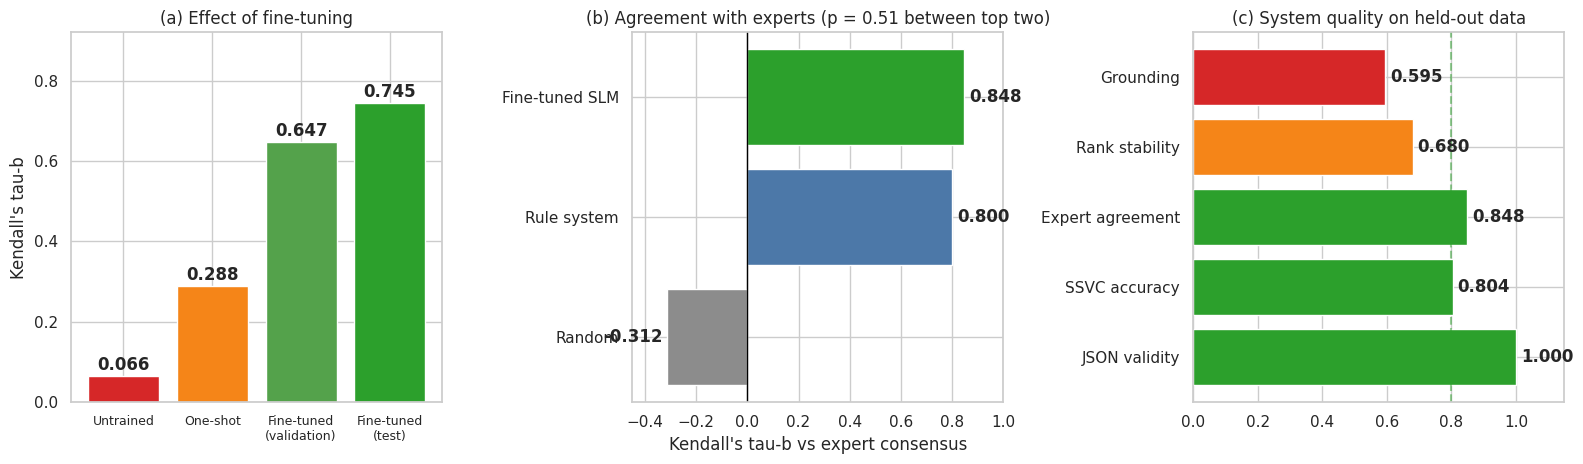

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))

prog = pd.DataFrame([{"condition":"Untrained","tau":0.066},{"condition":"One-shot","tau":0.288},
                     {"condition":"Fine-tuned\n(validation)","tau":0.647},
                     {"condition":"Fine-tuned\n(test)","tau":0.745}])
b = ax[0].bar(prog["condition"], prog["tau"], color=["#D62728","#F58518","#54A24B","#2CA02C"])
for r,v in zip(b, prog["tau"]):
    ax[0].text(r.get_x()+r.get_width()/2, v+.015, f"{v:.3f}", ha="center", fontweight="bold")
ax[0].set_ylabel("Kendall's tau-b"); ax[0].set_ylim(0,.92)
ax[0].set_title("(a) Effect of fine-tuning"); ax[0].tick_params(axis="x", labelsize=9)

vs = pd.DataFrame([{"system":"Random","tau":-0.312},{"system":"Rule system","tau":0.800},
                   {"system":"Fine-tuned SLM","tau":0.848}])
cols = ["#8C8C8C","#4C78A8","#2CA02C"]
b2 = ax[1].barh(vs["system"], vs["tau"], color=cols)
for r,v in zip(b2, vs["tau"]):
    ax[1].text(v + (.02 if v>0 else -.02), r.get_y()+r.get_height()/2, f"{v:.3f}",
               va="center", ha="left" if v>0 else "right", fontweight="bold")
ax[1].axvline(0, color="black", lw=1); ax[1].set_xlim(-.45,1.0)
ax[1].set_xlabel("Kendall's tau-b vs expert consensus")
ax[1].set_title("(b) Agreement with experts (p = 0.51 between top two)")

q = pd.DataFrame([{"m":"JSON validity","v":1.00},{"m":"SSVC accuracy","v":0.804},
                  {"m":"Expert agreement","v":0.848},{"m":"Rank stability","v":0.680},
                  {"m":"Grounding","v":0.595}])
b3 = ax[2].barh(q["m"], q["v"], color=["#2CA02C" if v>=.8 else "#F58518" if v>=.6 else "#D62728" for v in q["v"]])
for r,v in zip(b3, q["v"]):
    ax[2].text(v+.015, r.get_y()+r.get_height()/2, f"{v:.3f}", va="center", fontweight="bold")
ax[2].set_xlim(0,1.15); ax[2].axvline(0.8, color="#2CA02C", ls="--", alpha=.5)
ax[2].set_title("(c) System quality on held-out data")

plt.tight_layout(); plt.savefig(FIG/"fig1_synthesis.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig1_synthesis.png","figures/fig1_synthesis.png")

### Figure 2 — objective coverage and design principles


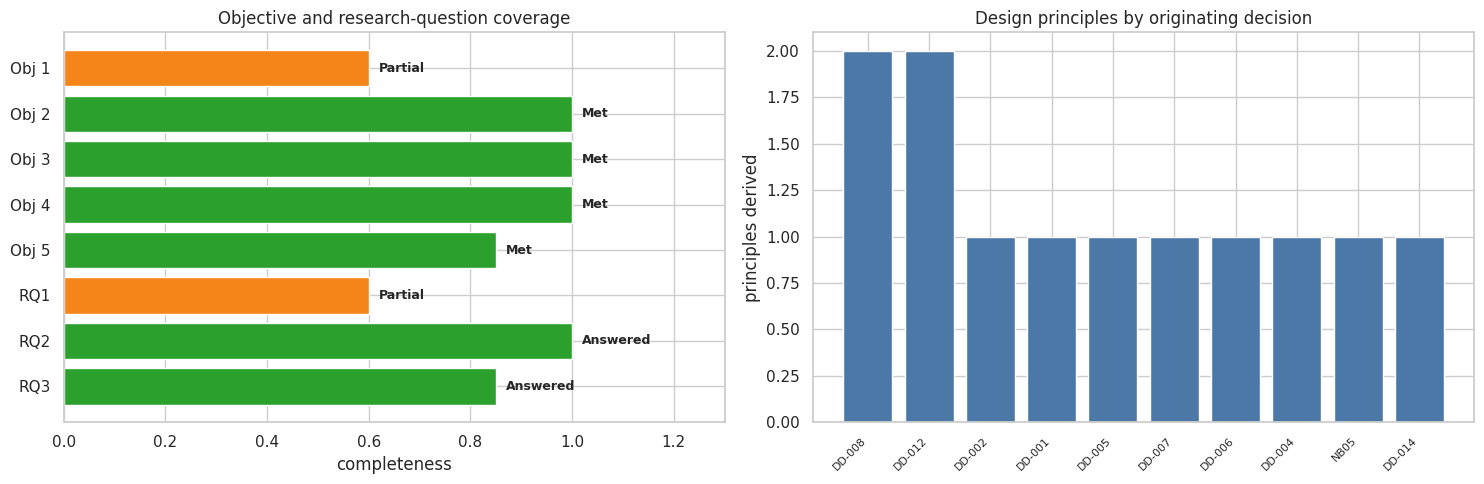

In [15]:
cov6 = pd.DataFrame([
 {"id":"Obj 1","status":"Partial","score":0.6,
  "evidence":"IaC-based discovery across three providers; runtime SDK enumeration is future work."},
 {"id":"Obj 2","status":"Met","score":1.0,
  "evidence":"Qwen2.5-3B QLoRA; test tau 0.745 against 0.066 untrained, p < 0.001."},
 {"id":"Obj 3","status":"Met","score":1.0,
  "evidence":"UFS, ranked reports at 100% JSON validity, explanations on every response, Streamlit interface."},
 {"id":"Obj 4","status":"Met","score":1.0,
  "evidence":"Held-out test with clustered CIs; 2 raters, W = 0.984; model vs experts tau 0.848."},
 {"id":"Obj 5","status":"Met","score":0.85,
  "evidence":"12 principles from 14 logged decisions; practitioner instrument built, study not yet run."},
 {"id":"RQ1","status":"Partial","score":0.6,
  "evidence":"Automated discovery demonstrated on IaC across AWS, Azure and GCP."},
 {"id":"RQ2","status":"Answered","score":1.0,
  "evidence":"tau 0.848 vs expert consensus; equivalent to a rule system (p = 0.51), with explanations."},
 {"id":"RQ3","status":"Answered","score":0.85,
  "evidence":"12 evidence-traced principles; empirical validation with practitioners outstanding."},
])
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
cmap = {"Met":"#2CA02C","Answered":"#2CA02C","Partial":"#F58518"}
b = ax[0].barh(cov6["id"], cov6["score"], color=[cmap[s] for s in cov6["status"]])
for r,(s,v) in zip(b, zip(cov6["status"], cov6["score"])):
    ax[0].text(v+.02, r.get_y()+r.get_height()/2, s, va="center", fontsize=9, fontweight="bold")
ax[0].set_xlim(0,1.3); ax[0].invert_yaxis()
ax[0].set_title("Objective and research-question coverage"); ax[0].set_xlabel("completeness")

src = pd.Series([p["from"].split(",")[0].strip() for p in PRINCIPLES]).value_counts()
ax[1].bar(range(len(src)), src.values, color="#4C78A8")
ax[1].set_xticks(range(len(src))); ax[1].set_xticklabels(src.index, rotation=45, ha="right", fontsize=8)
ax[1].set_ylabel("principles derived"); ax[1].set_title("Design principles by originating decision")

plt.tight_layout(); plt.savefig(FIG/"fig2_coverage.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig2_coverage.png","figures/fig2_coverage.png")
cov6.to_csv(TAB/"final_coverage.csv", index=False); mirror(TAB/"final_coverage.csv","tables/final_coverage.csv")

## 8 · Reporting pack


In [16]:
manifest = {
 "created_utc": datetime.now(timezone.utc).isoformat(),
 "notebook":"06_prototype_principles_synthesis.ipynb",
 "model": MODEL_ID, "adapter": str(ap), "gpu": GPU,
 "headline_results":{
   "untrained_tau":0.066, "oneshot_tau":0.288,
   "finetuned_validation_tau":0.647, "finetuned_test_tau":0.745,
   "model_vs_expert_tau":0.848, "rule_system_vs_expert_tau":0.800,
   "random_vs_expert_tau":-0.312, "interrater_W":0.984,
   "json_validity":1.0, "ssvc_accuracy":0.804,
   "rank_stability":0.680, "grounding_precision":0.595,
   "model_vs_rule_p_value":0.506,
 },
 "consolidated_results": RESULTS.to_dict("records"),
 "design_log": DESIGN_LOG,
 "design_principles": PRINCIPLES,
 "coverage": cov6.to_dict("records"),
 "artefacts":{
   "unified_finding_schema":"mcasm/schema/ufs.py",
   "prototype_report":"sample_report.txt",
   "streamlit_app":"app/app.py",
   "expert_instrument":"expert_annotation_workbook.xlsx",
   "practitioner_instrument":"practitioner_walkthrough.xlsx",
 },
 "claims_supported":[
   "A 3B parameter model fine-tuned on 1,200 ranking instances achieves tau 0.745 on a held-out "
   "test split, against 0.066 untrained and 0.288 with one-shot prompting (p < 0.001).",
   "Against an independent two-rater expert consensus the model reaches tau 0.848, compared with "
   "0.800 for a hand-engineered rule system and -0.312 for random ordering.",
   "Fine-tuning raised structured-output validity from 73.3% to 100% and SSVC class accuracy from "
   "6.5% to 80.4%.",
   "Test performance exceeded validation performance by 0.098, indicating no overfitting to the "
   "development split.",
 ],
 "claims_not_supported":[
   "That the model outperforms the rule-based system. The 0.048 advantage carries p = 0.506 over "
   "six ranking sets; the systems are statistically indistinguishable.",
   "That the system is suitable for autonomous remediation ordering. Rank stability (0.680) is "
   "below its agreement with experts, and 40.5% of explanation claims were unsupported.",
   "That discovery covers live cloud environments. Enumeration operates on Infrastructure-as-Code.",
 ],
 "limitations":[
   "Discovery is IaC-based; runtime SDK enumeration across AWS, Azure and GCP is future work.",
   "Expert study used 2 raters over 45 findings in 6 sets; the comparison is underpowered to "
   "detect differences smaller than roughly 0.2 tau.",
   "Inter-rater concordance (W = 0.984) is well above the 0.4-0.7 typically reported for "
   "vulnerability prioritisation, likely reflecting the prescriptive rubric and the clear "
   "separation of indicator profiles in the sample.",
   "Single training seed; run-to-run variance is not quantified.",
   "Practitioner walkthrough instrument is built but the study has not been conducted, so the "
   "design principles rest on construction evidence rather than user validation.",
   "Corpus derives from vulnerable-by-design repositories, which over-represent misconfiguration "
   "relative to production estates.",
 ],
 "future_work":[
   "Live SDK collectors for AWS, Azure and GCP against free-tier or emulated accounts.",
   "Graph enrichment for cross-resource privilege-escalation paths and true blast radius.",
   "Multi-seed training to quantify variance.",
   "Larger expert panel to power the model-versus-heuristic comparison.",
   "Practitioner walkthrough (n = 3-5) to validate the design principles.",
 ],
}
(RUN/"manifest_06.json").write_text(json.dumps(manifest, indent=2, default=str))

assets = RUN/"report_pack"; assets.mkdir(exist_ok=True)
shutil.copytree(FIG, assets/"figures", dirs_exist_ok=True)
shutil.copytree(TAB, assets/"tables", dirs_exist_ok=True)
shutil.copytree(APP, assets/"app", dirs_exist_ok=True)
for f in ("manifest_06.json","sample_report.txt","practitioner_walkthrough.xlsx"):
    if (RUN/f).exists(): shutil.copy(RUN/f, assets/f)
if S5.exists():
    shutil.copytree(S5, assets/"stage5", dirs_exist_ok=True)
shutil.make_archive("/content/mcasm_final_report_pack","zip",assets)
mirror(assets,"report_pack"); mirror("/content/mcasm_final_report_pack.zip","mcasm_final_report_pack.zip")

print("FIGURES:"); [print("  ",p.name) for p in sorted(FIG.glob("*.png"))]
print("TABLES :"); [print("  ",p.name) for p in sorted(TAB.glob("*.csv"))]
print("APP    :"); [print("  ",p.name) for p in sorted(APP.glob("*"))]
print(f"\npack: {Path('/content/mcasm_final_report_pack.zip').stat().st_size/1024**2:.1f} MiB")

FIGURES:
   fig1_synthesis.png
   fig2_coverage.png
TABLES :
   consolidated_results.csv
   design_log.csv
   design_principles.csv
   final_coverage.csv
APP    :
   app.py
   app_data.json

pack: 0.4 MiB


In [17]:
from google.colab import files
try: files.download("/content/mcasm_final_report_pack.zip")
except Exception: print("download failed — retrieve from Drive")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9 · Finish


In [18]:
print("="*70)
print("PROJECT COMPLETE")
print("="*70)
print(f"{'Untrained baseline':<38} tau 0.066")
print(f"{'One-shot prompting':<38} tau 0.288")
print(f"{'Fine-tuned (held-out test)':<38} tau 0.745")
print(f"{'Fine-tuned vs expert consensus':<38} tau 0.848")
print(f"{'Rule system vs expert consensus':<38} tau 0.800   (p = 0.51 vs model)")
print()
print(f"{'JSON validity':<38} 100%")
print(f"{'SSVC accuracy':<38} 80.4%")
print(f"{'Rank stability':<38} 0.680")
print(f"{'Grounding precision':<38} 0.595")
print()
print("Objectives 2, 3, 4, 5 met. Objective 1 partial (IaC-based discovery).")
print("RQ2 and RQ3 answered. RQ1 partially answered.")
print()
print("Outstanding: practitioner walkthrough (instrument ready, n = 3-5).")
print("="*70)
kill_runtime("Notebook finished.")

PROJECT COMPLETE
Untrained baseline                     tau 0.066
One-shot prompting                     tau 0.288
Fine-tuned (held-out test)             tau 0.745
Fine-tuned vs expert consensus         tau 0.848
Rule system vs expert consensus        tau 0.800   (p = 0.51 vs model)

JSON validity                          100%
SSVC accuracy                          80.4%
Rank stability                         0.680
Grounding precision                    0.595

Objectives 2, 3, 4, 5 met. Objective 1 partial (IaC-based discovery).
RQ2 and RQ3 answered. RQ1 partially answered.

Outstanding: practitioner walkthrough (instrument ready, n = 3-5).

Disconnecting runtime. Notebook finished.


## Figure reference

| Figure | File | Report section |
|---|---|---|
| 1 | `fig1_synthesis.png` | Results — headline findings |
| 2 | `fig2_coverage.png` | Discussion — objective coverage |
| — | `sample_report.txt` | Appendix — prototype output |
| — | `app/app.py` | Appendix — interface source |

## Writing the results chapter

**Lead with the comparison, not the number.** τ = 0.848 means little alone; τ = 0.848 against
0.800 for a rule system and −0.312 for random ordering, with two-rater consensus at W = 0.984,
is a result.

**Report the null finding prominently.** The model does not significantly outperform the
heuristic (p = 0.506). Framing this as equivalence-plus-explainability is both accurate and
more interesting than a marginal win would be: it says a small local model matches hand-built
expertise while producing justifications the heuristic cannot.

**Let the weaknesses do work.** Rank stability of 0.680 sits *below* agreement with experts,
which bounds trust in the ranking. Grounding precision of 0.595 means two in five explanation
claims are unsupported. Together they support Principle 12 — assistive deployment — and that
recommendation is a contribution in its own right.

**State the scope of Objective 1 plainly.** Discovery operates on Infrastructure-as-Code. Say
so in the methodology, restate it in limitations, and carry it into future work. A clearly
bounded scope reads far better than an overstated one.
